In [1]:
from astropy.table import Table, setdiff,join, unique
from matplotlib import pyplot as plt
import numpy as np


In [2]:
alma_regions = Table.read('../output/tables/glimpse_s07/alma_regions_YSO.tbl',format='ascii.ipac')

class_I_60 = []
class_II_60 = []
#print(spitzer_sources['p1_class_I'][alma_regions['p1_class_I'] > 0])
class_0_20 = []

class_I_20 = []
class_II_20 = []

SURFD_to_nH2 = (
        
        6.022e23  # Avogadro's constant (N_A) [particles/mol]
        / 2.016  # molecular mass of n(H2) [g/mol]
    )


for region in alma_regions:

        L_M = np.log10(region['LUM'] / region['MASS'])
        L = region['LUM']
        M = region['MASS']
        dist = region['DIST_AG']
        T = region['TBOL']
        NH_2 = region['NODEC_SURFD']*SURFD_to_nH2

        #if region['class_I_60'] != 0 and region['class_I_60'] != 1:
        class_I_60.append([L_M,L,M,dist,T,NH_2, region['rat_class_I_60']*100])
        #if region['class_II_60'] != 0 and region['class_II_60'] != 1:
        class_II_60.append([L_M,L,M,dist,T,NH_2, region['rat_class_II_60']*100])
        #if region['class_0_20'] != 0:
        class_0_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_0_20']*100])
        #if region['class_I_20'] != 0:
        class_I_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_I_20']*100])
        #if region['class_II_20'] != 0:
        class_II_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_II_20']*100])

In [33]:
alma_sources = Table.read('../output/tables/glimpse_s07/alma_sources_to_analyze.tbl',format='ascii.ipac')

print(alma_sources)

 ID       CLUMP            X         Y     ... p1_class_I p1_class_II p1_noclass
--- ------------------ --------- --------- ... ---------- ----------- ----------
  1             100132 897.03558  807.0044 ...         --          --         --
  2             100132 796.61502 862.99532 ...         --          --         --
  4             100244 468.07833 931.00007 ...         --          --         --
  1             100309 768.08734 459.99554 ...         --          --         --
  4             100309 637.45593 672.99884 ...         --          --         --
  8             100309 712.37732  683.0011 ...         --          --         --
  9             100309  642.2586 684.00324 ...         --          --         --
 10             100309 608.64019 683.00097 ...         --          --         --
 12             100309 696.04825 692.00105 ...         --          --         --
 16             100309 620.16646 729.99563 ...         --          --         --
...                ...      

In [381]:
spitzer_sources = Table.read('../output/tables/glimpse_s07/spitzer_sources_to_analyze.tbl',format='ascii.ipac')
alma_regions = Table.read('../output/tables/glimpse_s07/alma_regions_to_analyze.tbl',format='ascii.ipac')

80


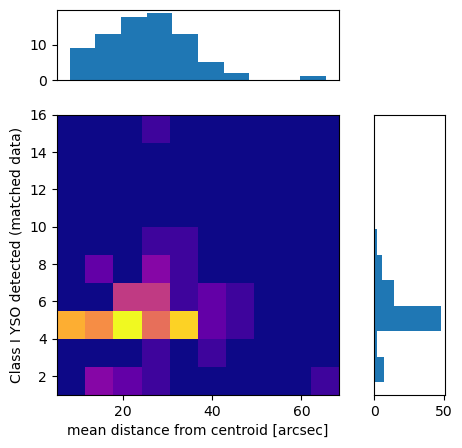

56


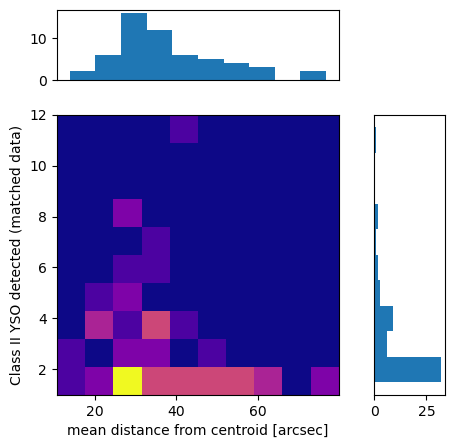

In [ ]:
n_regions = 1017
mode = 'total'
cat = 'glimpse_s07'

labels = ['Class I', 'Class II']
tbl = Table.read('../output/tables/'+cat+'/'+str(n_regions)+'_distance_'+str(mode)+'.tbl',format='ascii.ipac')
tbl = tbl[tbl['false_dist'] == 'False']




for idx,data in enumerate([['dist_class_I', 'class_I'],['dist_class_II','class_II']]):
    fig, axs = plt.subplots(2,2,figsize=(5,5),gridspec_kw={
        'width_ratios': [4, 1],
        'height_ratios': [1, 4]
    })

    xdata = np.array(tbl[data[0]][tbl[data[0]] != -999.0])
    ydata = np.array(tbl[data[1]][tbl[data[0]] != -999.0])
    print(len(xdata))
    xdata = xdata*3600

    axs[0][1].axis('off')
    axs[1][0].hist2d(xdata,ydata,cmap='plasma')

    axs[0][0].hist(xdata)
    axs[1][1].hist(ydata,orientation='horizontal')


    '''axs[0][0].set_xlim([0,40])
    axs[0][0].set_ylim([0,12])
    axs[1][1].set_ylim([0,4])
    axs[1][1].set_xlim([0,50])

    axs[1][0].set_xlim([0,40])
    axs[1][0].set_ylim([0,4])'''

    '''counts, _ = np.histogram(tbl['class_I']+tbl['class_II'],bins=range(0,np.max(tbl['class_I']+tbl['class_II'])+1,1))

    '''
    axs[1][0].set_xlabel('mean distance from centroid [arcsec]')
    axs[1][0].set_ylabel(labels[idx]+' YSO detected (matched data)')

    axs[0][0].tick_params(axis='x', bottom=False, labelbottom=False)
    axs[1][1].tick_params(axis='y', left=False, labelleft=False)
    axs[1][1].tick_params(axis='y', which='minor',left=False, labelleft=False)

    fig.savefig('../output/figures/'+cat+'/'+data[1]+'_distance_YSO.pdf',format='pdf',dpi=300)
    plt.show()
    plt.close()

83
1.8878642419325418: 79.78550152132644


C:\Users\Alex\AppData\Local\Temp\ipykernel_14460\2112201508.py:238: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  rect, connectors = axs[0].indicate_inset_zoom(axs[1],edgecolor='k',linestyle='--',linewidth=3)


1.8878642419325418: 39.882420906120814


C:\Users\Alex\AppData\Local\Temp\ipykernel_14460\2112201508.py:238: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  rect, connectors = axs[0].indicate_inset_zoom(axs[1],edgecolor='k',linestyle='--',linewidth=3)


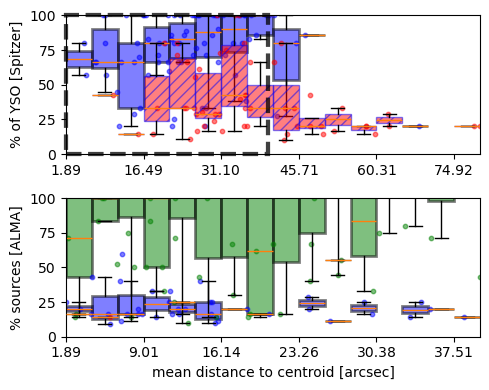

In [7]:
n_regions = 1017
mode = 'total'
cat = 'glimpse_s07'

labels = ['Class I', 'Class II']
tbl = Table.read('../output/tables/'+cat+'/'+str(n_regions)+'_distance_'+str(mode)+'.tbl',format='ascii.ipac')

tbl = tbl[tbl['false_dist'] == 'False']
print(len(tbl))

aux = np.array(tbl['class_I']+tbl['class_II'])
    
count_I = np.array(tbl['class_I']) / aux  
count_II = np.array(tbl['class_II']) / aux

aux2 = np.array(tbl['class_0']+tbl['radio']+tbl['class_I_alma']+tbl['class_II_alma'])
    
count_0 = np.array(tbl['class_0']) / aux  
count_radio = np.array(tbl['radio']) / aux
count_I_alma = np.array(tbl['class_I_alma']) / aux  
count_II_alma = np.array(tbl['class_II_alma']) / aux


for idx, count in enumerate(count_I):
    if np.isnan(count):
        count_I[idx] = 0

for idx, count in enumerate(count_II):
    if np.isnan(count):
        count_II[idx] = 0

for idx, count in enumerate(count_0):
    if np.isnan(count):
        count_0[idx] = 0

for idx, count in enumerate(count_radio):
    if np.isnan(count):
        count_radio[idx] = 0

for idx, count in enumerate(count_I_alma):
    if np.isnan(count):
        count_I_alma[idx] = 0

for idx, count in enumerate(count_II_alma):
    if np.isnan(count):
        count_II_alma[idx] = 0



tbl['rat_class_I'] = count_I
tbl['rat_class_II'] = count_II

tbl['rat_class_0'] = count_0
tbl['rat_radio'] = count_radio
tbl['rat_class_I_alma'] = count_I_alma
tbl['rat_class_II_alma'] = count_II_alma

tbl.write('../output/tables/glimpse_s07/final_plot.tbl',format='ascii.ipac',overwrite=True)

fig, axs = plt.subplots(2,1,figsize=(5,4),tight_layout=True)

color_list = [['blue','red'], ['lightgrey','darkgrey']]

for idx, data_set in enumerate([
    [['dist_class_I','dist_class_II','dist_class_I_alma','dist_class_II_alma'],['rat_class_I','rat_class_II','rat_class_I_alma','rat_class_II_alma']],
    [['dist_class_I_alma','dist_class_II_alma','dist_class_0','dist_class_radio'],['rat_class_I_alma','rat_class_II_alma','rat_class_0','rat_radio',]]
    ]):

    if idx == 0:
        data = [
            [tbl[data_set[0][0]][tbl[data_set[0][0]] != -999], tbl[data_set[1][0]][tbl[data_set[0][0]] != -999]],
            [tbl[data_set[0][1]][tbl[data_set[0][1]] != -999], tbl[data_set[1][1]][tbl[data_set[0][1]] != -999]],
            [tbl[data_set[0][2]][tbl[data_set[0][2]] != -999], tbl[data_set[1][2]][tbl[data_set[0][2]] != -999]],
            [tbl[data_set[0][3]][tbl[data_set[0][3]] != -999], tbl[data_set[1][3]][tbl[data_set[0][3]] != -999]]
        ]
        
        x1, y1 = np.array(data[0][0])*3600,np.array(data[0][1])*100
        x2, y2 = np.array(data[1][0])*3600,np.array(data[1][1]) *100
        x3, y3 = np.array(data[2][0])*3600,np.array(data[2][1])*100
        x4, y4 = np.array(data[3][0])*3600, np.array(data[3][1]) *100
    else:
        data = [
            [tbl[data_set[0][0]][tbl[data_set[0][0]] != -999], tbl[data_set[1][0]][tbl[data_set[0][0]] != -999]],
            [tbl[data_set[0][1]][tbl[data_set[0][1]] != -999], tbl[data_set[1][1]][tbl[data_set[0][1]] != -999]],
            [tbl[data_set[0][2]][tbl[data_set[0][2]] != -999], tbl[data_set[1][2]][tbl[data_set[0][2]] != -999]],
            [tbl[data_set[0][3]][tbl[data_set[0][3]] != -999], tbl[data_set[1][3]][tbl[data_set[0][3]] != -999]]
        ]

        x1, y1 = np.array(data[0][0])*3600,np.array(data[0][1])*100
        x2, y2 = np.array(data[1][0])*3600,np.array(data[1][1]) *100
        x3, y3 = np.array(data[2][0])*3600,np.array(data[2][1])*100
        x4, y4 = np.array(data[3][0])*3600, np.array(data[3][1]) *100

    if idx == 0:
        min = np.min([np.min(x1),np.min(x2),np.min(x3),np.min(x4)])
        max = np.max([np.max(x1),np.max(x2),np.max(x3),np.max(x4)])
    if idx == 1:
        min_2 = np.min([np.min(x1),np.min(x2),np.min(x3),np.min(x4)])
        max_2 = np.max([np.max(x1),np.max(x2),np.max(x3),np.max(x4)])

        min = np.min([min,min_2])
        max = np.min([max,max_2])
    print(f'{min}: {max}')
    n_bins = 15
    step = (max-min)/(n_bins+1)
    bins = np.arange(min, max+step, step)

    groups1, groups2,groups3, groups4 = [], [], [], []
    pos1, pos2, pos3, pos4 = [], [], [], []

    offset = step/50  # spacing between boxplots

    for i in range(len(bins) - 1):
        mask1 = (x1 >= bins[i]) & (x1 < bins[i+1])
        mask2 = (x2 >= bins[i]) & (x2 < bins[i+1])
        mask3 = (x3 >= bins[i]) & (x3 < bins[i+1])
        mask4 = (x4 >= bins[i]) & (x4 < bins[i+1])

        center = (bins[i] + bins[i+1]) / 2

        if np.sum(mask1) > 0:
            pos1.append(center)
            groups1.append(y1[mask1])
        if np.sum(mask2) > 0:
            pos2.append(center)
            groups2.append(y2[mask2])
        if np.sum(mask3) > 0:
            pos3.append(center)
            groups3.append(y3[mask3])
        if np.sum(mask4) > 0:
            pos4.append(center)
            groups4.append(y4[mask4])

    
    
    if idx == 0:

        # Class I 

        bp1 = axs[0].boxplot(
            groups1,
            positions=pos1,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=2
        )

        for box in bp1['boxes']:
            box.set(facecolor='blue', alpha=0.5, edgecolor='black',linewidth=2,zorder=0)

        axs[0].scatter(x1,y1,color='blue',s=10,alpha=0.5)
        # Class II
        
        bp2 = axs[0].boxplot(
            groups2,
            positions=pos2,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=3
        )
        
        for box in bp2['boxes']:
            box.set(facecolor='red', alpha=0.5, edgecolor=color_list[idx][0],hatch='///',linewidth=1)
        axs[0].scatter(x2,y2,color='red',s=10,alpha=0.5)
    if idx == 1:
        
        # Class I ALMA

        bp1 = axs[1].boxplot(
            groups1,
            positions=pos1,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=2
        )

        for box in bp1['boxes']:
            box.set(facecolor='blue', alpha=0.5, edgecolor='black',linewidth=2,zorder=0)
        axs[1].scatter(x1,y1,color='blue',s=10,alpha=0.5)
        
        # Class II ALMA

        bp2 = axs[1].boxplot(
            groups2,
            positions=pos2,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=3
        )
        
        for box in bp2['boxes']:
            box.set(facecolor='red', alpha=0.5, edgecolor=color_list[idx][0],hatch='///',linewidth=1)
        axs[1].scatter(x2,y2,color='red',s=10,alpha=0.5)
        
        # Class 0

        bp3 = axs[idx].boxplot(
            groups3,
            positions=pos3,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=2
        )
        axs[1].scatter(x3,y3,color='green',s=10,alpha=0.5)
        for box in bp3['boxes']:
            box.set(facecolor='green', alpha=0.5, edgecolor='black',linewidth=2,zorder=0)

        # radio

        bp4 = axs[idx].boxplot(
            groups4,
            positions=pos4,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=3
        )
        axs[1].scatter(x4,y4,color='darkgreen',s=10,alpha=0.5)
        for box in bp4['boxes']:
            box.set(facecolor='darkgreen', alpha=0.5, edgecolor='black',hatch='///',linewidth=1,zorder=2)

    axs[idx].set_xlim(min,max)
    axs[0].set_ylim([0,100])
    axs[1].set_ylim([0,100])
    
    axs[1].set_xlabel('mean distance to centroid [arcsec]')

    if idx == 0:
        axs[0].set_ylabel(r'% of YSO [Spitzer]')
    else:
        axs[1].set_ylabel(r'% sources [ALMA]')
    
    rect, connectors = axs[0].indicate_inset_zoom(axs[1],edgecolor='k',linestyle='--',linewidth=3)

    

    for c in connectors:
        c.set_visible(False)
        c.set_linestyle('--')
        c.set_linewidth(3)


    ticks = bins[::3]

    axs[idx].set_xticks(ticks, [f"{t:.2f}" for t in ticks])

#fig.savefig('../output/figures/'+cat+'/results_distance_YSO.pdf',format='pdf',dpi=300)

In [ ]:
def function(alma_regions):
    
    # MARK: L/M, L, M, T, DIST, N(H_2)

    class_I_60 = []
    class_II_60 = []
    class_0_20 = []
    class_I_20 = []
    class_II_20 = []
    radio_20 = []

    SURFD_to_nH2 = (
        
        6.022e23  # Avogadro's constant (N_A) [particles/mol]
        / 2.016  # molecular mass of n(H2) [g/mol]
    )

    for region in alma_regions:

        if (
            region['MASS'] == -999 or
            region['LUM'] == -999 or
            region['TBOL'] == -999 or 
            region['DIST_AG'] == -999 or
            region['NODEC_SURFD'] == -999
        ):
            continue
        
        L_M = np.log10(region['LUM'] / region['MASS'])
        L = np.log10(region['LUM'])
        M = np.log10(region['MASS'])
        dist = np.log10(region['DIST_AG'])
        T = np.log10(region['TBOL'])
        NH_2 = np.log10(region['NODEC_SURFD']*SURFD_to_nH2)


        class_I_60.append([L_M,L,M,dist,T,NH_2, region['rat_class_I_60']*100])
        class_II_60.append([L_M,L,M,dist,T,NH_2, region['rat_class_II_60']*100])
        class_0_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_0_20']*100])
        class_I_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_I_20']*100])
        class_II_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_II_20']*100])
        radio_20.append([L_M,L,M,dist,T,NH_2, region['rat_radio_20']*100])

    xlabels = [r'log L/M [L$_\odot$/M$_\odot$]', r'log L [L$_\odot$]', r'log M [M$_\odot$]', 'log distance [pc]', r'log T$_{\text{bol}}$ [K]', r'log N(H$_2$) [cm$^{-2}$]']

    for idx, plot in enumerate(['L_M','L','M','dist','T','NH_2']):

        fig, axs = plt.subplots(2,1,figsize=(5,4),tight_layout=True,sharex=True)

        for idx2,data_set in enumerate([[class_I_60,class_II_60,class_0_20, radio_20],[class_I_20,class_II_20,class_0_20, radio_20]]):

            data_1 = [[x[idx] for x in data_set[0]],[x[-1] for x in data_set[0]]]
            data_2 = [[x[idx] for x in data_set[1]],[x[-1] for x in data_set[1]]]
            data_3 = [[x[idx] for x in data_set[2]],[x[-1] for x in data_set[2]]]
            data_4 = [[x[idx] for x in data_set[3]],[x[-1] for x in data_set[3]]]

            x1, y1 = np.array(data_1[0]),np.array(data_1[1])
            x2, y2 = np.array(data_2[0]), np.array(data_2[1])
            x3, y3 = np.array(data_3[0]), np.array(data_3[1])
            x4, y4 = np.array(data_4[0]), np.array(data_4[1])
            

            if idx2 == 0:
                min = round(10*np.min([np.min(x1),np.min(x2),np.min(x3),np.min(x4)]))/10
                max = round(10*np.max([np.max(x1),np.max(x2),np.max(x3),np.max(x4)]))/10
                n_bins = 12
                step = (max-min)/(n_bins)
                bins = np.arange(min, max+step, step)

            

            groups1, groups2, groups3,groups4 = [], [], [], []
            pos1, pos2, pos3, pos4 = [], [], [], []

            #offset = step/50  # spacing between boxplots

            offset = 0

            for i in range(len(bins) - 1):
                mask1 = (x1 >= bins[i]) & (x1 < bins[i+1])
                mask2 = (x2 >= bins[i]) & (x2 < bins[i+1])
                mask3 = (x3 >= bins[i]) & (x3 < bins[i+1])
                mask4 = (x4 >= bins[i]) & (x4 < bins[i+1])

                center = (bins[i] + bins[i+1]) / 2

                if np.sum(mask1) > 0:
                    pos1.append(center)
                    groups1.append(y1[mask1])
                    
                if np.sum(mask2) > 0:
                    pos2.append(center + offset)
                    groups2.append(y2[mask2])
                if np.sum(mask3) > 0:
                    pos3.append(center - offset)       
                    groups3.append(y3[mask3])
                if np.sum(mask4) > 0:
                    pos4.append(center - 2*offset)       
                    groups4.append(y4[mask4])


            # Class I

            bp1 = axs[idx2].boxplot(
                groups1,
                positions=pos1,
                widths=step,
                patch_artist=True,
                showfliers=False,
                zorder=2
            )
            axs[idx2].scatter(x1,y1,color='blue',s=10,alpha=0.6,zorder=20)
            for box in bp1['boxes']:
                box.set(facecolor='blue', alpha=0.5, edgecolor='black',linewidth=2,zorder=0)

            # Class II

            bp2 = axs[idx2].boxplot(
                groups2,
                positions=pos2,
                widths=step,
                patch_artist=True,
                showfliers=False,
                zorder=3
            )
            axs[idx2].scatter(x2,y2,color='red',s=10,alpha=0.6,zorder=20)
            for box in bp2['boxes']:
                box.set(facecolor='red', alpha=0.4, edgecolor='red',hatch='///',linewidth=1,zorder=1)


        # Class 0

        bp0 = axs[1].boxplot(
            groups3,
            positions=pos3,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=1
        )
        
        for box in bp0['boxes']:
            box.set(facecolor='limegreen', alpha=0.5,edgecolor='black')
        axs[1].scatter(x3,y3,color='darkgreen',s=10,alpha=0.3,zorder=20)

        bp3 = axs[1].boxplot(
            groups4,
            positions=pos4,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=0
        )
        axs[1].scatter(x4,y4,color='orange',s=10,alpha=0.6,zorder=20)
        for box in bp3['boxes']:
            box.set(facecolor='gold', alpha=0.4,edgecolor='black',hatch='///')


        axs[0].set_xlim(min,max)
        axs[0].set_ylim([-5,105])
        axs[1].set_ylim([-5,105])

        axs[1].set_xlabel(f'{xlabels[idx]}')
        axs[0].set_ylabel(r'% of YSO [Spitzer]')
        axs[1].set_ylabel(r'% of YSO [ALMA]')

        ticks = bins[::2]

        axs[1].set_xticks(ticks, [f"{t:.2f}" for t in ticks])
        if idx2 == 1:
            fig.savefig('../output/figures/'+cat+'/results_'+plot+'.pdf',format='pdf',dpi=300)
            plt.show()
            plt.close()

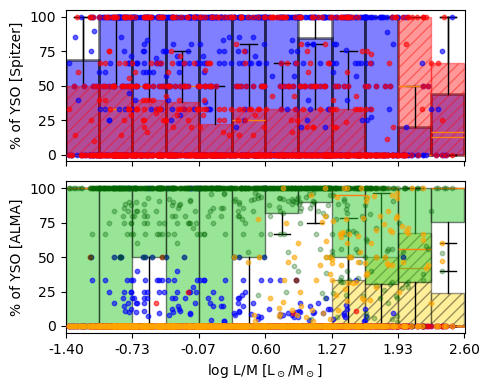

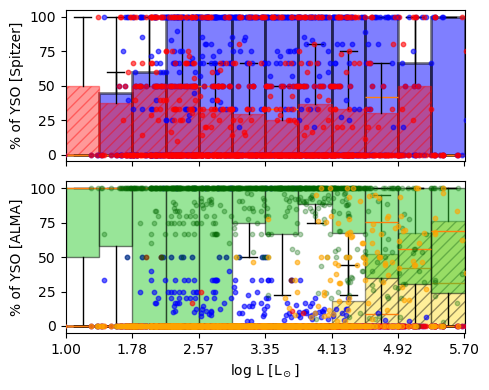

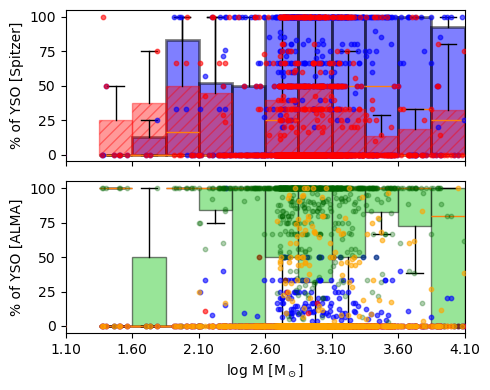

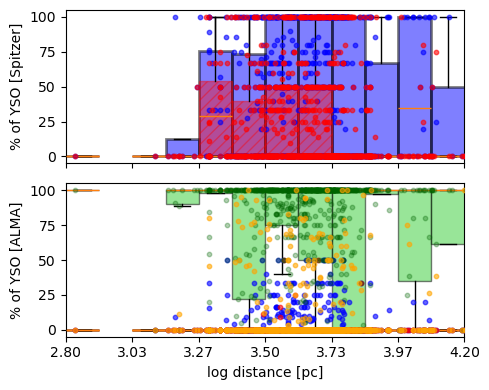

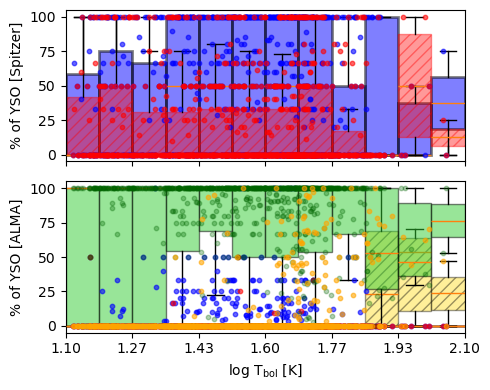

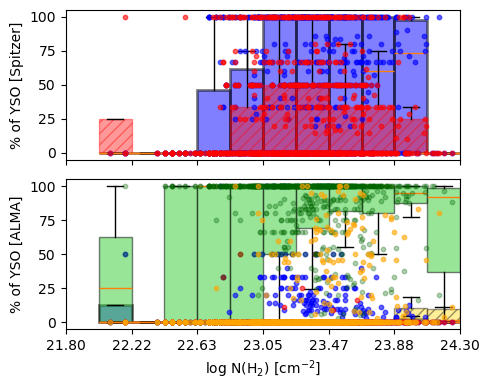

In [223]:

function(alma_regions)

In [80]:
tbl = Table.read('../output/tables/glimpse_s07/1017_distance_total.tbl',format='ascii.ipac')
tbl['region_id'][tbl['false_dist'] == 'True']

881644
57335
56634
765992
133522
65099
128764
744588
743353
737579
131513


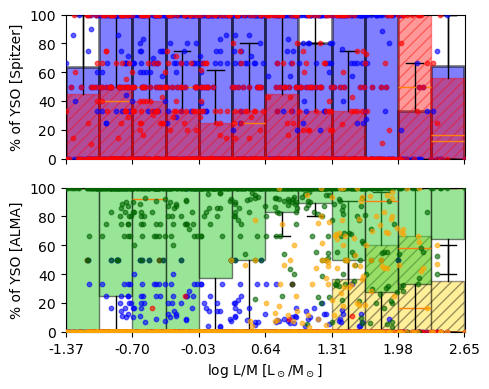

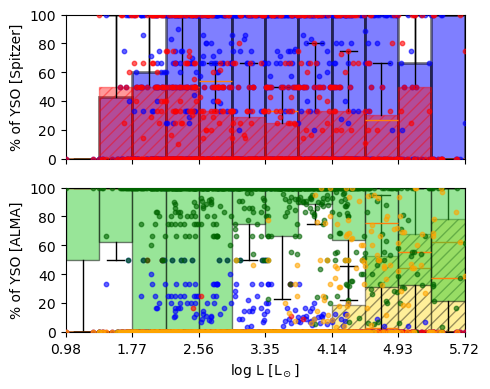

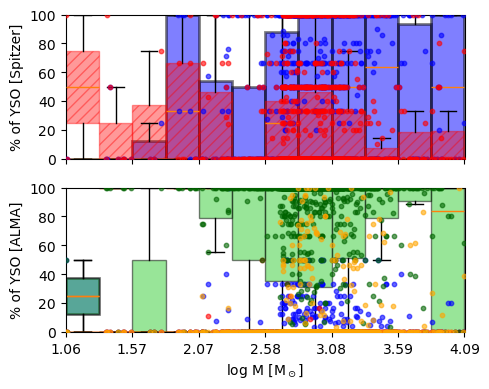

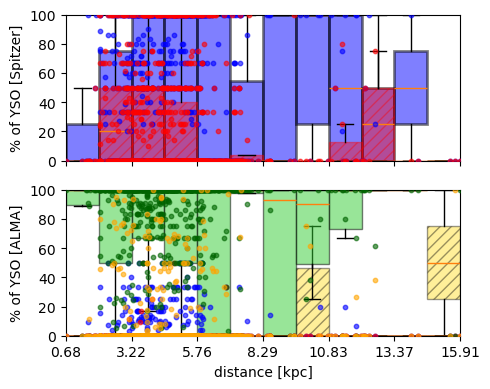

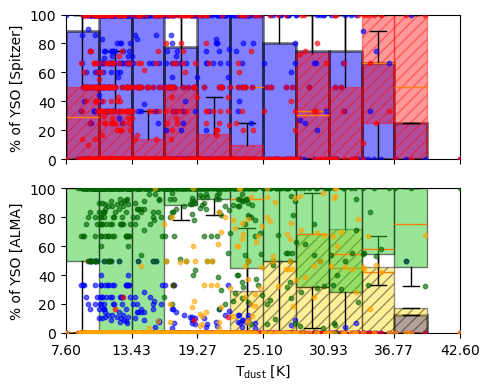

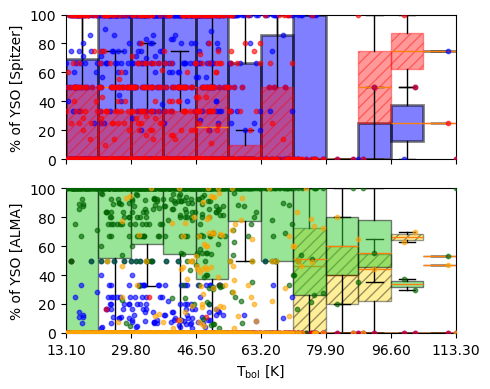

In [4]:
# MARK: L/M, L, M, T, DIST, N(H_2)
cat = 'glimpse_s07'
class_I_60 = []
class_II_60 = []
class_0_20 = []
class_I_20 = []
class_II_20 = []
radio_20 = []

SURFD_to_nH2 = (
    
    6.022e23  # Avogadro's constant (N_A) [particles/mol]
    / 2.016  # molecular mass of n(H2) [g/mol]
)
#limits = [[-1.5,2.6],[1,6],[1.5,4],[0.5,13],[10,100],[22,24]]

for region in alma_regions:

    if (
        region['MASS'] == -999 or
        region['LUM'] == -999 or
        region['TDUST'] == -999 or
        region['TBOL'] == -999 or 
        region['DIST_AG'] == -999 or
        region['NODEC_SURFD'] == -999
    ):
        continue
    
    L_M = np.log10(region['LUM'] / region['MASS'])
    L = np.log10(region['LUM'])
    M = np.log10(region['MASS'])
    dist = np.array(region['DIST_AG']) / 1000
    TDUST = np.array(region['TDUST'])
    TBOL = np.array(region['TBOL'])
    NH_2 = np.log10(region['NODEC_SURFD']*SURFD_to_nH2)


    class_I_60.append([L_M,L,M,dist,TDUST,TBOL,NH_2, region['rat_class_I_60']*100])
    class_II_60.append([L_M,L,M,dist,TDUST,TBOL,NH_2, region['rat_class_II_60']*100])
    class_0_20.append([L_M,L,M,dist,TDUST,TBOL,NH_2, region['rat_class_0_20']*100])
    class_I_20.append([L_M,L,M,dist,TDUST,TBOL,NH_2, region['rat_class_I_20']*100])
    class_II_20.append([L_M,L,M,dist,TDUST,TBOL,NH_2, region['rat_class_II_20']*100])
    radio_20.append([L_M,L,M,dist,TDUST,TBOL,NH_2, region['rat_radio_20']*100])

xlabels = [r'log L/M [L$_\odot$/M$_\odot$]', r'log L [L$_\odot$]', r'log M [M$_\odot$]', 'distance [kpc]',r'T$_{\text{dust}}$ [K]', r'T$_{\text{bol}}$ [K]', r'log N(H$_2$) [cm$^{-2}$]']

for idx, plot in enumerate(['L_M','L','M','dist','T','NH_2']):

    fig, axs = plt.subplots(2,1,figsize=(5,4),tight_layout=True,sharex=True)

    for idx2,data_set in enumerate([[class_I_60,class_II_60,class_0_20, radio_20],[class_I_20,class_II_20,class_0_20, radio_20]]):

        data_1 = [[x[idx] for x in data_set[0]],[x[-1] for x in data_set[0]]]
        data_2 = [[x[idx] for x in data_set[1]],[x[-1] for x in data_set[1]]]
        data_3 = [[x[idx] for x in data_set[2]],[x[-1] for x in data_set[2]]]
        data_4 = [[x[idx] for x in data_set[3]],[x[-1] for x in data_set[3]]]

        x1, y1 = np.array(data_1[0]),np.array(data_1[1])
        x2, y2 = np.array(data_2[0]), np.array(data_2[1])
        x3, y3 = np.array(data_3[0]), np.array(data_3[1])
        x4, y4 = np.array(data_4[0]), np.array(data_4[1])
        
        '''x1 = x1[(y1 != 0 ) & (y1 != 100)]
        y1 = y1[(y1 != 0 ) & (y1 != 100)]

        x2 = x2[(y2 != 0 ) & (y2 != 100)]
        y2 = y2[(y2 != 0 ) & (y2 != 100)]

        x3 = x3[(y3 != 0 ) & (y3 != 100)]
        y3 = y3[(y3 != 0 ) & (y3 != 100)]

        x4 = x4[(y4 != 0 ) & (y4 != 100)]
        y4 = y4[(y4 != 0 ) & (y4 != 100)]'''

        
        


        
        #min, max = limits[idx][0],limits[idx][1]
        min, max = np.min([np.min(x1),np.min(x2),np.min(x3),np.min(x4)]), np.max([np.max(x1),np.max(x2),np.max(x3),np.max(x4)])
        n_bins = 12
        step = (max-min)/(n_bins)
        bins = np.arange(min, max+step, step)
        

        

        groups1, groups2, groups3, groups4 = [], [], [], []
        pos1, pos2, pos3, pos4 = [], [], [], []

        #offset = step/50  # spacing between boxplots

        offset = 0

        for i in range(len(bins) - 1):
            mask1 = (x1 >= bins[i]) & (x1 < bins[i+1])
            mask2 = (x2 >= bins[i]) & (x2 < bins[i+1])
            mask3 = (x3 >= bins[i]) & (x3 < bins[i+1])
            mask4 = (x4 >= bins[i]) & (x4 < bins[i+1])

            center = (bins[i] + bins[i+1]) / 2

            if np.sum(mask1) > 0:
                pos1.append(center)
                groups1.append(y1[mask1])
                
            if np.sum(mask2) > 0:
                pos2.append(center + offset)
                groups2.append(y2[mask2])
            if np.sum(mask3) > 0:
                pos3.append(center - offset)       
                groups3.append(y3[mask3])
            if np.sum(mask4) > 0:
                pos4.append(center - 2*offset)       
                groups4.append(y4[mask4])


        # Class I
        axs[idx2].scatter(x1,y1,color='blue',s=10,alpha=0.6,zorder=20)
        bp1 = axs[idx2].boxplot(
            groups1,
            positions=pos1,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=2
        )
        
        for box in bp1['boxes']:
            box.set(facecolor='blue', alpha=0.5, edgecolor='black',linewidth=2,zorder=0)

        # Class II

        bp2 = axs[idx2].boxplot(
            groups2,
            positions=pos2,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=3
        )
        axs[idx2].scatter(x2,y2,color='red',s=10,alpha=0.6,zorder=20)
        for box in bp2['boxes']:
            box.set(facecolor='red', alpha=0.4, edgecolor='red',hatch='///',linewidth=1,zorder=1)


    # Class 0

    bp0 = axs[1].boxplot(
        groups3,
        positions=pos3,
        widths=step,
        patch_artist=True,
        showfliers=False,
        zorder=1
    )
    
    for box in bp0['boxes']:
        box.set(facecolor='limegreen', alpha=0.5,edgecolor='black')
    axs[1].scatter(x3,y3,color='darkgreen',s=10,alpha=0.6,zorder=20)

    bp3 = axs[1].boxplot(
        groups4,
        positions=pos4,
        widths=step,
        patch_artist=True,
        showfliers=False,
        zorder=0
    )
    axs[1].scatter(x4,y4,color='orange',s=10,alpha=0.6,zorder=20)
    for box in bp3['boxes']:
        box.set(facecolor='gold', alpha=0.4,edgecolor='black',hatch='///')


    axs[0].set_xlim(min,max)
    axs[0].set_ylim([0,100])
    axs[1].set_ylim([0,100])

    axs[1].set_xlabel(f'{xlabels[idx]}')
    axs[0].set_ylabel(r'% of YSO [Spitzer]')
    axs[1].set_ylabel(r'% of YSO [ALMA]')

    ticks = bins[::2]

    axs[1].set_xticks(ticks, [f"{t:.2f}" for t in ticks])
    if idx2 == 1:
        fig.savefig('../output/figures/'+cat+'/results_'+plot+'.pdf',format='pdf',dpi=300)
        plt.show()
        plt.close()


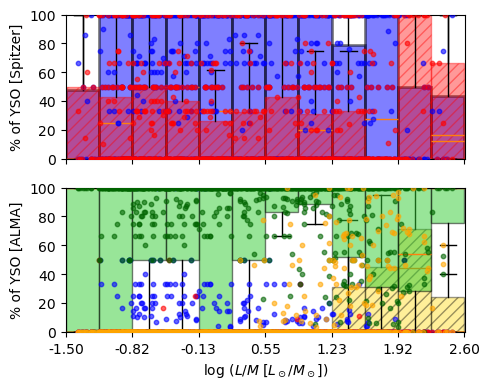

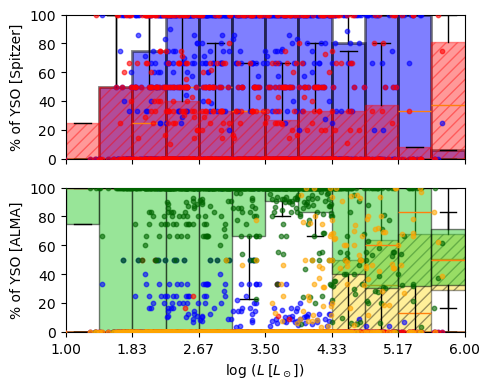

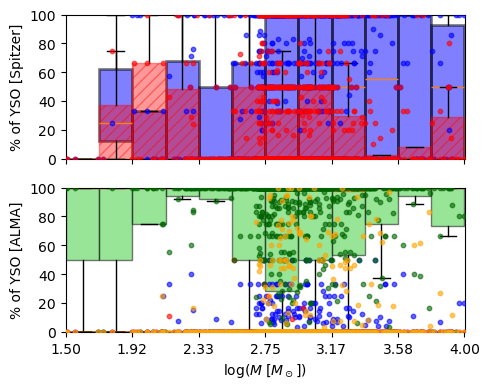

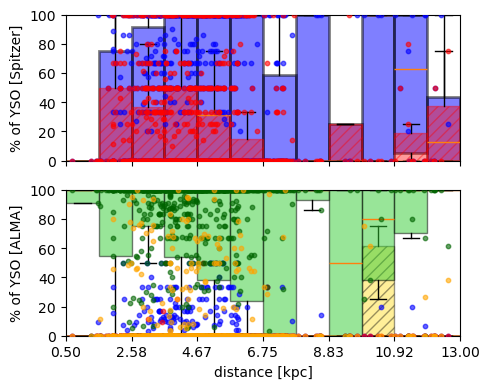

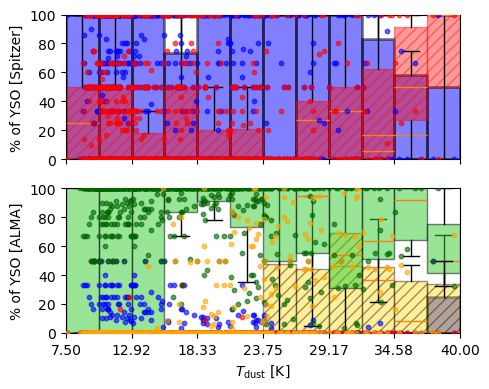

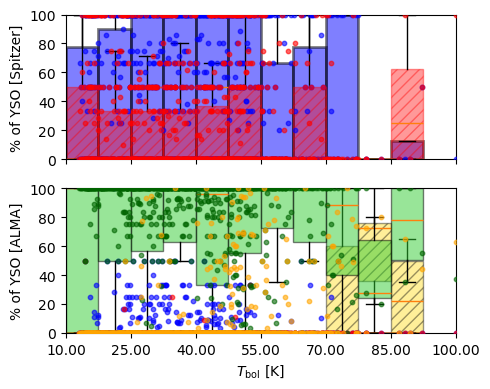

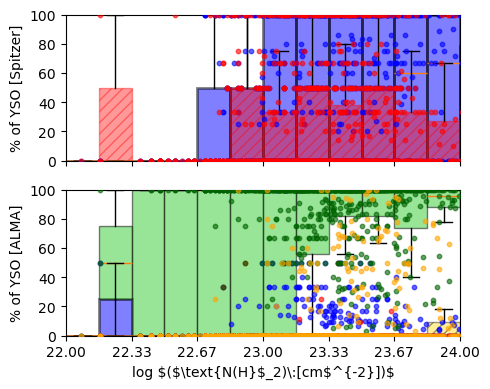

In [10]:
# MARK: L/M, L, M, T, DIST, N(H_2)
cat = 'glimpse_s07'
class_I_60 = []
class_II_60 = []
class_0_20 = []
class_I_20 = []
class_II_20 = []
radio_20 = []

SURFD_to_nH2 = (
    
    6.022e23  # Avogadro's constant (N_A) [particles/mol]
    / 2.016  # molecular mass of n(H2) [g/mol]
)
limits = [[-1.5,2.6],[1,6],[1.5,4],[0.5,13],[7.5,40],[10,100],[22,24]]

for region in alma_regions:

    if (
        region['MASS'] == -999 or
        region['LUM'] == -999 or
        region['TDUST'] == -999 or
        region['TBOL'] == -999 or 
        region['DIST_AG'] == -999 or
        region['NODEC_SURFD'] == -999
    ):
        continue
    
    L_M = np.log10(region['LUM'] / region['MASS'])
    L = np.log10(region['LUM'])
    M = np.log10(region['MASS'])
    dist = np.array(region['DIST_AG']) / 1000
    TDUST = np.array(region['TDUST'])
    TBOL = np.array(region['TBOL'])
    NH_2 = np.log10(region['NODEC_SURFD']*SURFD_to_nH2)


    class_I_60.append([L_M,L,M,dist,TDUST,TBOL,NH_2, region['rat_class_I_60']*100])
    class_II_60.append([L_M,L,M,dist,TDUST,TBOL,NH_2, region['rat_class_II_60']*100])
    class_0_20.append([L_M,L,M,dist,TDUST,TBOL,NH_2, region['rat_class_0_20']*100])
    class_I_20.append([L_M,L,M,dist,TDUST,TBOL,NH_2, region['rat_class_I_20']*100])
    class_II_20.append([L_M,L,M,dist,TDUST,TBOL,NH_2, region['rat_class_II_20']*100])
    radio_20.append([L_M,L,M,dist,TDUST,TBOL,NH_2, region['rat_radio_20']*100])

xlabels = [r'log $\left(L/M\; [L_\odot/M_\odot]\right)$', r'log $\left(L\;[L_\odot]\right)$', r'log$\left(M\;[M_\odot]\right)$', 'distance [kpc]',r'$T_{\text{dust}}$ [K]', r'$T_{\text{bol}}$ [K]', r'log $($\text{N(H}$_2)\:[cm$^{-2}])$']

for idx, plot in enumerate(['L_M','L','M','dist','Tdust','Tbol','NH_2']):

    fig, axs = plt.subplots(2,1,figsize=(5,4),tight_layout=True,sharex=True)

    for idx2,data_set in enumerate([[class_I_60,class_II_60,class_0_20, radio_20],[class_I_20,class_II_20,class_0_20, radio_20]]):

        data_1 = [[x[idx] for x in data_set[0]],[x[-1] for x in data_set[0]]]
        data_2 = [[x[idx] for x in data_set[1]],[x[-1] for x in data_set[1]]]
        data_3 = [[x[idx] for x in data_set[2]],[x[-1] for x in data_set[2]]]
        data_4 = [[x[idx] for x in data_set[3]],[x[-1] for x in data_set[3]]]

        x1, y1 = np.array(data_1[0]),np.array(data_1[1])
        x2, y2 = np.array(data_2[0]), np.array(data_2[1])
        x3, y3 = np.array(data_3[0]), np.array(data_3[1])
        x4, y4 = np.array(data_4[0]), np.array(data_4[1])
        
        '''x1 = x1[(y1 != 0 ) & (y1 != 100)]
        y1 = y1[(y1 != 0 ) & (y1 != 100)]

        x2 = x2[(y2 != 0 ) & (y2 != 100)]
        y2 = y2[(y2 != 0 ) & (y2 != 100)]

        x3 = x3[(y3 != 0 ) & (y3 != 100)]
        y3 = y3[(y3 != 0 ) & (y3 != 100)]

        x4 = x4[(y4 != 0 ) & (y4 != 100)]
        y4 = y4[(y4 != 0 ) & (y4 != 100)]'''

        
        


        
        min, max = limits[idx][0],limits[idx][1]
        #min, max = np.min([np.min(x1),np.min(x2),np.min(x3),np.min(x4)]), np.max([np.max(x1),np.max(x2),np.max(x3),np.max(x4)])
        n_bins = 12
        step = (max-min)/(n_bins)
        bins = np.arange(min, max+step, step)
        

        

        groups1, groups2, groups3, groups4 = [], [], [], []
        pos1, pos2, pos3, pos4 = [], [], [], []

        #offset = step/50  # spacing between boxplots

        offset = 0

        for i in range(len(bins) - 1):
            mask1 = (x1 >= bins[i]) & (x1 < bins[i+1])
            mask2 = (x2 >= bins[i]) & (x2 < bins[i+1])
            mask3 = (x3 >= bins[i]) & (x3 < bins[i+1])
            mask4 = (x4 >= bins[i]) & (x4 < bins[i+1])

            center = (bins[i] + bins[i+1]) / 2

            if np.sum(mask1) > 0:
                pos1.append(center)
                groups1.append(y1[mask1])
                
            if np.sum(mask2) > 0:
                pos2.append(center + offset)
                groups2.append(y2[mask2])
            if np.sum(mask3) > 0:
                pos3.append(center - offset)       
                groups3.append(y3[mask3])
            if np.sum(mask4) > 0:
                pos4.append(center - 2*offset)       
                groups4.append(y4[mask4])


        # Class I
        axs[idx2].scatter(x1,y1,color='blue',s=10,alpha=0.6,zorder=20)
        bp1 = axs[idx2].boxplot(
            groups1,
            positions=pos1,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=2
        )
        
        for box in bp1['boxes']:
            box.set(facecolor='blue', alpha=0.5, edgecolor='black',linewidth=2,zorder=0)

        # Class II

        bp2 = axs[idx2].boxplot(
            groups2,
            positions=pos2,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=3
        )
        axs[idx2].scatter(x2,y2,color='red',s=10,alpha=0.6,zorder=20)
        for box in bp2['boxes']:
            box.set(facecolor='red', alpha=0.4, edgecolor='red',hatch='///',linewidth=1,zorder=1)


    # Class 0

    bp0 = axs[1].boxplot(
        groups3,
        positions=pos3,
        widths=step,
        patch_artist=True,
        showfliers=False,
        zorder=1
    )
    
    for box in bp0['boxes']:
        box.set(facecolor='limegreen', alpha=0.5,edgecolor='black')
    axs[1].scatter(x3,y3,color='darkgreen',s=10,alpha=0.6,zorder=20)

    bp3 = axs[1].boxplot(
        groups4,
        positions=pos4,
        widths=step,
        patch_artist=True,
        showfliers=False,
        zorder=0
    )
    axs[1].scatter(x4,y4,color='orange',s=10,alpha=0.6,zorder=20)
    for box in bp3['boxes']:
        box.set(facecolor='gold', alpha=0.4,edgecolor='black',hatch='///')


    axs[0].set_xlim(min,max)
    axs[0].set_ylim([0,100])
    axs[1].set_ylim([0,100])

    axs[1].set_xlabel(f'{xlabels[idx]}')
    axs[0].set_ylabel(r'% of YSO [Spitzer]')
    axs[1].set_ylabel(r'% of YSO [ALMA]')

    ticks = bins[::2]

    axs[1].set_xticks(ticks, [f"{t:.2f}" for t in ticks])
    if idx2 == 1:
        fig.savefig('../output/figures/'+cat+'/results_'+plot+'.pdf',format='pdf',dpi=300)
        plt.show()
        plt.close()


In [49]:
a =(alma_sources['ID','CLUMP','HAS_SPITZER'][(alma_sources['HAS_SPITZER'] == 'True')])
print(a)

 ID       CLUMP        HAS_SPITZER
--- ------------------ -----------
 11             101899        True
  1             103575        True
  2             103575        True
  1             103916        True
  6             104080        True
  4             104173        True
  8             104316        True
  2             104344        True
 18             104579        True
 10             105028        True
...                ...         ...
  3  G337.1555-00.3951        True
  8  G337.1555-00.3951        True
 13  G337.1555-00.3951        True
 13 G337.4050-00.4071A        True
  8  G338.9196+00.5495        True
 11  G338.9196+00.5495        True
  1 G340.0543-00.2437D        True
  7  G340.7455-01.0021        True
 22  G340.7455-01.0021        True
  3  G343.9033-00.6713        True
Length = 388 rows


In [51]:
len(unique(a, keys=["CLUMP",'ID']))

388

In [54]:
n_class_I

[np.float64(-0.7658434986502473),
 np.float64(-1.2404912834206503),
 np.float64(-0.03689804154200282),
 np.float64(1.084519261623048),
 np.float64(-0.43227309023219107),
 np.float64(-0.01102401186693966),
 np.float64(-0.4346112379413825),
 np.float64(-0.450777385374814),
 np.float64(1.7034947063083985),
 np.float64(-0.8244152068698261),
 np.float64(-0.4986821723630566),
 np.float64(-0.9672194197049899),
 np.float64(-0.2868332020427903),
 np.float64(-0.9287499523988969),
 np.float64(1.1756037840519975),
 np.float64(1.314592352024615),
 np.float64(2.028123527437769),
 np.float64(-0.35071508028427983),
 np.float64(1.2728321442382724),
 np.float64(0.046244223392870196),
 np.float64(-0.5970157118121675),
 np.float64(-0.5228290519932642),
 np.float64(0.9032563167226098),
 np.float64(0.17689350841556628),
 np.float64(-0.2117338306883506),
 np.float64(0.8798584189928591),
 np.float64(1.610641623699815),
 np.float64(0.2403973661134932),
 np.float64(0.8725003352248288),
 np.float64(1.50290659653

In [8]:
tbl = Table.read('../output/tables/'+cat+'/'+str(n_regions)+'_distance_'+str(mode)+'.tbl',format='ascii.ipac')


In [29]:
print(sum(tbl['radio'][tbl['false_dist'] == 'False']))

60


In [30]:
alma_sources

NameError: name 'alma_sources' is not defined